# 04 · Replica sul 2017: il test funziona su persone nuove?

Tutto ciò che è stato costruito finora (profili, ordine delle domande, modello) viene dal sondaggio **2015**. Un risultato utile per un'azienda deve funzionare su **persone diverse, in un momento diverso**.

Il sondaggio **2017** :
- **Nuovi utenti**, 1.676 rispondenti utilizzabili, raccolte due anni dopo;
- **una scala diversa**, con l'opzione "indifferente" che nel 2015 non esisteva;
- **nessun ricalcolo**: applico esattamente la divisione del catalogo, i centri dei profili, l'ordine delle domande e i modelli del 2015.

Le domande sono due:
1. I 5 Caratteri **esistono anche nel 2017**, o erano un artefatto del 2015?
2. Il test progettato sul 2015 **riconosce i Caratteri del 2017**, e la curva domande-accuratezza ha la stessa forma?

In [1]:
import json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment
from sklearn.cluster import KMeans
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score, adjusted_rand_score
from catalogo import ATTRIBUTI
from stile_grafici import applica_stile, salva, BLU, ARANCIO, ACQUA, GRIGIO, TESTO_2

warnings.filterwarnings("ignore", category=FutureWarning)
applica_stile()
SEED = 42

M15 = pd.read_csv("../data/processed/valutazioni_2015.csv", index_col="persona")
M17 = pd.read_csv("../data/processed/valutazioni_2017.csv", index_col="persona")
ctx15 = pd.read_csv("../data/processed/contesto_2015.csv", index_col="persona")
ctx17 = pd.read_csv("../data/processed/contesto_2017.csv", index_col="persona")
cat = pd.read_csv("../data/processed/catalogo.csv").set_index("dolce")
divisione = json.load(open("../data/processed/divisione_catalogo.json"))
PROFILO, DOMANDE_GUSTO = divisione["profilo"], divisione["domande"]
centri15 = pd.read_csv("../data/processed/centri_profili_2015.csv", index_col=0)
profili15 = pd.read_csv("../data/processed/profili_2015.csv", index_col="persona")["carattere"]
ord_info = json.load(open("../data/processed/ordine_domande_2015.json"))
ORDINE, C = ord_info["ordine"], ord_info["C"]
NOMI = list(centri15.index)
print(f"2015: {len(M15):,} persone · 2017: {len(M17):,} persone · ordine delle domande: {len(ORDINE)} domande")

2015: 4,579 persone · 2017: 1,676 persone · ordine delle domande: 20 domande


## 1. Le due scale a confronto

Nel 2017 circa un terzo delle risposte è "indifferente", codificato a 0,5 nel notebook 01. Prima di confrontare i profili verifico che **l'ordine di gradimento dei dolci** sia simile nei due anni: se i dolci più amati nel 2015 sono gli stessi del 2017, le scale sono confrontabili nella sostanza.

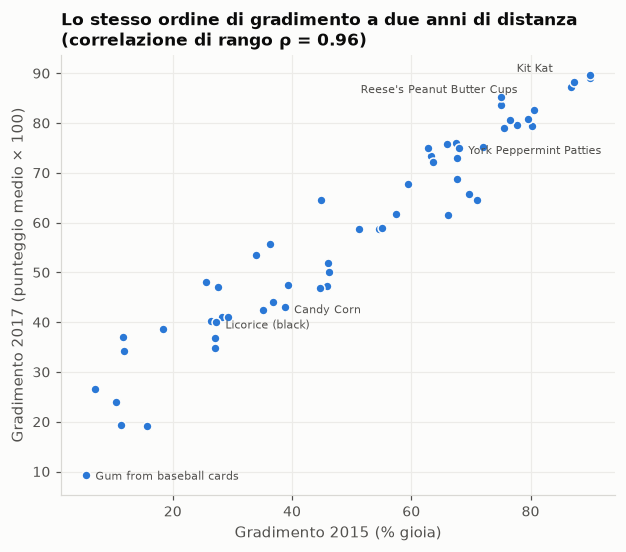

Correlazione di rango tra gradimento 2015 e 2017: ρ = 0.96


In [2]:
gioia15 = M15.mean()
gioia17 = M17.mean()
r_spearman = gioia15.rank().corr(gioia17.rank())

fig, ax = plt.subplots(figsize=(6.5, 5.2))
ax.scatter(gioia15 * 100, gioia17 * 100, s=34, color=BLU, edgecolor="#fcfcfb", linewidth=1)
for d, off in {"Kit Kat": (-48, 4), "Reese's Peanut Butter Cups": (-150, -12), "Licorice (black)": (6, -4),
               "Gum from baseball cards": (6, -3), "Candy Corn": (6, -4), "York Peppermint Patties": (6, -4)}.items():
    ax.annotate(d, (gioia15[d] * 100, gioia17[d] * 100), xytext=off, textcoords="offset points", fontsize=7.5, color=TESTO_2)
ax.set_xlabel("Gradimento 2015 (% gioia)"); ax.set_ylabel("Gradimento 2017 (punteggio medio × 100)")
ax.set_title(f"Lo stesso ordine di gradimento a due anni di distanza\n(correlazione di rango ρ = {r_spearman:.2f})", fontsize=11)
ax.grid(axis="x")
salva(fig, "04_gradimento_2015_vs_2017")
plt.show()
print(f"Correlazione di rango tra gradimento 2015 e 2017: ρ = {r_spearman:.2f}")

I dolci più amati e quelli più detestati sono **gli stessi nei due anni** (ρ = 0,96): in cima Kit Kat e Reese's, in fondo liquirizia nera e *gum from baseball cards*.

I valori assoluti del 2017 sono più vicini al centro, come atteso: l'opzione "indifferente" sposta i giudizi verso 0,5. Ma l'**ordine relativo**, che è ciò su cui si basano i profili, è conservato.

## 2. I Caratteri esistono anche nel 2017?

Calcolo i punteggi sensoriali del 2017 con gli **stessi 38 dolci** del profilo. Li standardizzo con media e deviazione **del 2017**, perché l'opzione "indifferente" restringe la scala e una standardizzazione comune penalizzerebbe artificialmente il 2017.

Poi:
- **(a)** assegno ogni persona del 2017 al centro 2015 più vicino. È ciò che farebbe il test in produzione;
- **(b)** rifaccio da zero una segmentazione a 5 profili *solo* sul 2017, senza sapere nulla del 2015, e guardo se ritrova gli stessi profili.

In [3]:
def punteggi_attributo(valutazioni, dolci):
    X = valutazioni[dolci]
    relativo = X.sub(X.mean(axis=1), axis=0)
    return pd.DataFrame({a: relativo[[d for d in dolci if cat.loc[d, a]]].mean(axis=1) for a in ATTRIBUTI}).fillna(0)

S17 = punteggi_attributo(M17, PROFILO)
Z17 = (S17 - S17.mean()) / S17.std()

# (a) assegnazione ai centri 2015
dist = ((Z17.values[:, None, :] - centri15.values[None, :, :]) ** 2).sum(axis=2)
profilo17 = pd.Series(np.array(NOMI)[dist.argmin(axis=1)], index=Z17.index)

# (b) segmentazione indipendente del 2017
km17 = KMeans(5, n_init=50, random_state=SEED).fit(Z17.values)
c17 = pd.DataFrame(km17.cluster_centers_, columns=ATTRIBUTI)
r_, c_ = linear_sum_assignment(-(centri15.values @ c17.values.T))
abbinamento = {c: NOMI[r] for r, c in zip(r_, c_)}
c17.index = [abbinamento[i] for i in c17.index]
c17 = c17.loc[NOMI]
indip17 = pd.Series(km17.labels_, index=Z17.index).map(abbinamento)

confronto = pd.DataFrame({
    "quota 2015": profili15.value_counts(normalize=True).reindex(NOMI),
    "quota 2017 (centri 2015)": profilo17.value_counts(normalize=True).reindex(NOMI),
    "correlazione centro 2015 vs centro 2017 indipendente": [np.corrcoef(centri15.loc[n], c17.loc[n])[0, 1] for n in NOMI],
})
print(f"Accordo tra (a) e (b): {(profilo17 == indip17).mean():.0%} delle persone nello stesso profilo "
      f"(ARI = {adjusted_rand_score(profilo17, indip17):.2f})\n")
confronto.round(2)

Accordo tra (a) e (b): 88% delle persone nello stesso profilo (ARI = 0.73)



,quota 2015,quota 2017 (centri 2015),correlazione centro 2015 vs centro 2017 indipendente
#Goloso,0.22,0.22,0.99
#Vivace,0.16,0.16,0.99
#Eccentrico,0.16,0.18,0.93
#Fresco,0.26,0.25,0.98
#Morbido,0.20,0.19,0.99


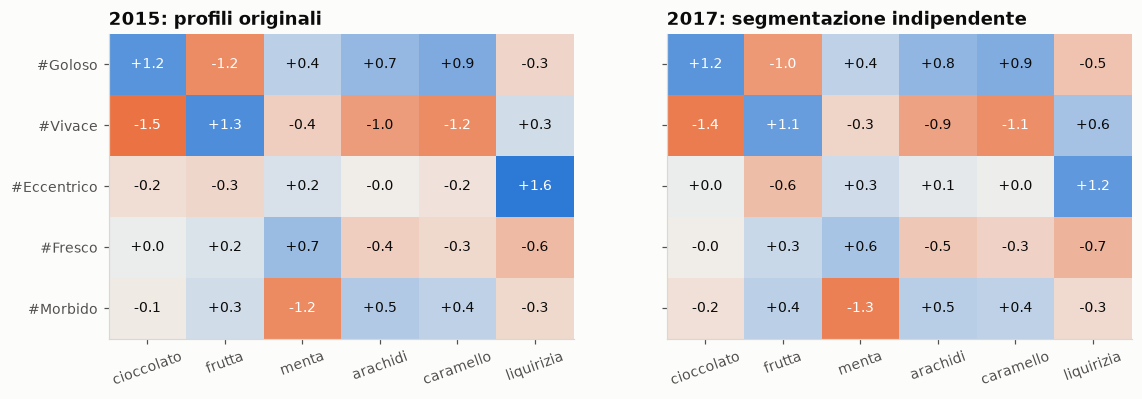

In [4]:
from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list("div", [ARANCIO, "#f1f0ed", BLU])
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for ax, tab, titolo in [(axes[0], centri15, "2015: profili originali"), (axes[1], c17, "2017: segmentazione indipendente")]:
    ax.imshow(tab.values, cmap=cmap, vmin=-1.6, vmax=1.6, aspect="auto")
    for i in range(tab.shape[0]):
        for j in range(tab.shape[1]):
            v = tab.iloc[i, j]
            ax.text(j, i, f"{v:+.1f}", ha="center", va="center", fontsize=9, color="white" if abs(v) > 1.0 else "#0b0b0b")
    ax.set_xticks(range(len(ATTRIBUTI)), ATTRIBUTI, rotation=20); ax.set_title(titolo); ax.grid(False)
axes[0].set_yticks(range(len(NOMI)), NOMI)
salva(fig, "04_profili_2015_vs_2017")
plt.show()

**I 5 Caratteri esistono anche nel 2017.**

- Una segmentazione fatta da zero sul 2017, senza alcuna informazione sul 2015, ritrova **gli stessi 5 profili**: correlazione tra i centri 0,93–0,99.
- Le **proporzioni** sono quasi identiche: #Goloso 22% in entrambi gli anni, #Vivace 16%, #Fresco 26% e 25%.
- L'88% delle persone del 2017 finisce nello stesso profilo sia con i centri del 2015 sia con la segmentazione indipendente.

Su persone diverse, con una scala diversa e a due anni di distanza, la struttura del gusto è la stessa. Il profilo **meno stabile** è #Eccentrico (correlazione 0,93): è definito dalla liquirizia, che nel catalogo è rappresentata da pochissimi dolci.

## 3. Il test del 2015 funziona sulle persone del 2017?

Ora la prova principale. Per ogni lunghezza del test, da 1 a 20 domande nell'**ordine scelto nel 2015**, addestro il modello su **tutto il 2015** e lo applico, senza modifiche, alle persone del 2017. Il bersaglio è il loro #Carattere, assegnato con i centri 2015.

**Come tratto la risposta "indifferente".** Nel 2015 non esisteva, quindi il modello non l'ha mai vista. Confronto due codifiche ragionevoli:
- **"come non risposto"**: nel 2015 chi era indifferente probabilmente saltava la domanda;
- **"a metà"**: metà gioia e metà delusione.

In [5]:
CONTESTO = ["eta"]
LIVELLI = {}   # categorie viste nel 2015, per avere le stesse colonne nel 2017

def blocco(serie, q, anno, meh="non_risposto"):
    if q in CONTESTO:
        X = pd.get_dummies(serie, prefix=q).astype(float)
    else:
        X = pd.DataFrame(index=serie.index)
        X[f"{q}_gioia"] = (serie == 1).astype(float)
        X[f"{q}_delusione"] = (serie == 0).astype(float)
        X[f"{q}_non_risposto"] = serie.isna().astype(float)
        indiff = serie == 0.5
        if meh == "non_risposto":
            X.loc[indiff, f"{q}_non_risposto"] = 1.0
        else:   # "a metà"
            X.loc[indiff, [f"{q}_gioia", f"{q}_delusione"]] = 0.5
    if anno == 2015:
        LIVELLI[q] = list(X.columns)
    return X.reindex(columns=LIVELLI[q], fill_value=0.0)

def matrice(M, ctx, anno, domande, meh="non_risposto"):
    return pd.concat([blocco(ctx[q] if q in CONTESTO else M[q], q, anno, meh) for q in domande], axis=1)

X15 = matrice(M15, ctx15, 2015, ORDINE)
y15 = profili15.loc[M15.index].map({n: i for i, n in enumerate(NOMI)}).to_numpy()
y17 = profilo17.loc[M17.index].map({n: i for i, n in enumerate(NOMI)}).to_numpy()
X17 = {meh: matrice(M17, ctx17, 2017, ORDINE, meh) for meh in ["non_risposto", "a_metà"]}

rng = np.random.default_rng(SEED)
boot_idx = [rng.integers(0, len(y17), len(y17)) for _ in range(2000)]
base17 = (y17 == np.bincount(y15).argmax()).mean()

righe = []
for k in range(1, len(ORDINE) + 1):
    cols = [c for q in ORDINE[:k] for c in LIVELLI[q]]
    m = LogisticRegression(C=C, max_iter=3000).fit(X15[cols], y15)
    riga = {"k": k, "domanda_aggiunta": ORDINE[k - 1]}
    for meh, X in X17.items():
        corretto = m.predict(X[cols]) == y17
        boot = [corretto[i].mean() for i in boot_idx]
        riga[f"acc_{meh}"] = corretto.mean()
        riga[f"ic_basso_{meh}"], riga[f"ic_alto_{meh}"] = np.percentile(boot, [2.5, 97.5])
    righe.append(riga)
trasferimento = pd.DataFrame(righe).set_index("k")
print(f"Nessuna domanda (tutti {NOMI[np.bincount(y15).argmax()]}): {base17:.1%}")
trasferimento[["domanda_aggiunta", "acc_non_risposto", "acc_a_metà", "ic_basso_a_metà", "ic_alto_a_metà"]].round(3)

Nessuna domanda (tutti #Fresco): 24.8%


,domanda_aggiunta,acc_non_risposto,acc_a_metà,ic_basso_a_metà,ic_alto_a_metà
k,,,,,
1,Nerds,0.298,0.298,0.276,0.320
2,100 Grand,0.308,0.309,0.288,0.331
3,Black Jacks,0.328,0.349,0.327,0.372
4,Hard Candy,0.319,0.355,0.332,0.377
5,Peanut M&M's,0.329,0.363,0.339,0.385
6,Skittles,0.328,0.374,0.350,0.397
7,Mars,0.331,0.382,0.359,0.405
8,Necco Wafers,0.333,0.382,0.358,0.406
9,Rolos,0.342,0.385,0.362,0.409


La codifica conta: trattare "indifferente" **a metà** funziona nettamente meglio che trattarlo come "non risposto", e il vantaggio cresce con il numero di domande. È plausibile: un "indifferente" è una vera opinione intermedia, non un'assenza di risposta.

Da qui in poi uso **"a metà" come codifica principale**. Va detto con trasparenza: la scelta è fatta guardando i risultati del 2017, quindi la stima che segue è *leggermente ottimistica*. Una verifica pulita richiederebbe un terzo anno di dati.

Per confronto calcolo anche la curva che si otterrebbe **ri-addestrando il modello sul 2017** (cross-validation, stesso ordine di domande). È il limite di ciò che il test potrebbe fare sapendo già come rispondono le persone del 2017. La distanza tra le due curve misura **quanto si perde trasferendo il test** da un anno all'altro.

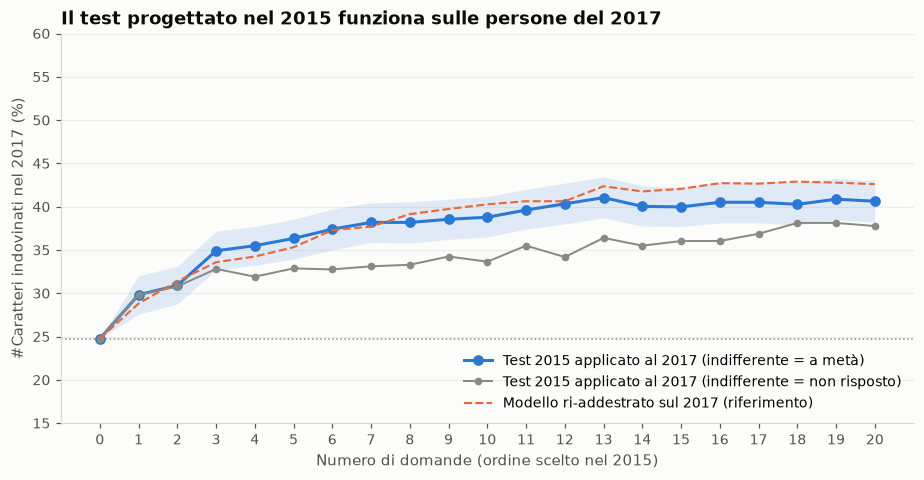

Modello ri-addestrato sul 2017 (CV): {1: 0.288, 7: 0.377, 12: 0.406, 20: 0.426}


In [6]:
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
interno17 = pd.Series({k: cross_val_score(LogisticRegression(C=C, max_iter=3000),
                                          X17["a_metà"][[c for q in ORDINE[:k] for c in LIVELLI[q]]], y17, cv=cv).mean()
                       for k in range(1, len(ORDINE) + 1)})

K = len(ORDINE); k_ax = np.arange(0, K + 1)
fig, ax = plt.subplots(figsize=(10, 4.6))
t = trasferimento
ax.fill_between(k_ax, np.r_[base17, t["ic_basso_a_metà"]] * 100, np.r_[base17, t["ic_alto_a_metà"]] * 100, color=BLU, alpha=0.13, linewidth=0)
ax.plot(k_ax, np.r_[base17, t["acc_a_metà"]] * 100, marker="o", color=BLU, markersize=6,
        label="Test 2015 applicato al 2017 (indifferente = a metà)")
ax.plot(k_ax, np.r_[base17, t["acc_non_risposto"]] * 100, marker="o", color=GRIGIO, markersize=4, linewidth=1.3,
        label="Test 2015 applicato al 2017 (indifferente = non risposto)")
ax.plot(k_ax, np.r_[base17, interno17.values] * 100, color=ARANCIO, linestyle="--", linewidth=1.4,
        label="Modello ri-addestrato sul 2017 (riferimento)")
ax.axhline(base17 * 100, color=GRIGIO, linestyle=":", linewidth=1)
ax.set_xticks(k_ax); ax.set_ylim(15, 60)
ax.set_xlabel("Numero di domande (ordine scelto nel 2015)"); ax.set_ylabel("#Caratteri indovinati nel 2017 (%)")
ax.set_title("Il test progettato nel 2015 funziona sulle persone del 2017")
ax.legend(loc="lower right")
salva(fig, "04_curva_trasferimento")
plt.show()
print("Modello ri-addestrato sul 2017 (CV):", interno17.loc[[1, 7, 12, len(ORDINE)]].round(3).to_dict())

In [7]:
acc_t = pd.Series(np.r_[base17, trasferimento["acc_a_metà"]], index=k_ax)
guadagno_t = (acc_t - base17) / (acc_t.max() - base17)
gomito_t = int(guadagno_t[guadagno_t >= 0.9].index.min())
print(f"Nel 2017 il 90% del guadagno massimo si raggiunge con {gomito_t} domande "
      f"({acc_t[gomito_t]:.1%}, massimo {acc_t.max():.1%}, senza domande {base17:.1%})")
pd.DataFrame({"trasferito (%)": acc_t * 100, "% del guadagno": guadagno_t * 100}).loc[[0, 1, 3, 5, 7, 8, 10, 12, 15, len(ORDINE)]].round(1).T

Nel 2017 il 90% del guadagno massimo si raggiunge con 11 domande (39.6%, massimo 41.1%, senza domande 24.8%)


,0,1,3,5,7,8,10,12,15,20
trasferito (%),24.8,29.8,34.9,36.3,38.2,38.2,38.8,40.3,40.0,40.6
% del guadagno,0.0,31.1,62.3,71.1,82.4,82.4,86.1,95.6,93.4,97.4


**Il test del 2015 funziona sulle persone del 2017, con la stessa forma della curva.**

| | 2015 (test set) | 2017 (test trasferito) | 2017 (ri-addestrato) |
|---|---|---|---|
| 0 domande | 26% | 25% | 25% |
| 1 domanda | 31% | 30% | 29% |
| 7 domande | 40% | 38% | 38% |
| 12 domande | 43% | 40% | 41% |
| 20 domande | 43% | 40,6% | 43% |

- **Il gomito è quasi nello stesso punto.** Nel 2017 il 90% del guadagno arriva con **11 domande**, contro le 12 del 2015.
- **Trasferire il test costa pochissimo.** Il modello del 2015 applicato al 2017 resta entro 1–2 punti da un modello ri-addestrato direttamente sul 2017. Ordine delle domande, profili e pesi del modello si possono riusare.
- **La perdita rispetto al 2015 è di 2–3 punti**, dovuta soprattutto al cambio di scala: con "indifferente" trattato come risposta mancante la perdita sarebbe molto più grande.

## 4. Conclusioni della replica

- **I Caratteri sono reali, non un artefatto del campione:** gli stessi 5 profili, con le stesse proporzioni, riemergono da zero su persone diverse due anni dopo.
- **Il disegno del test si trasferisce.** L'ordine delle domande scelto sul 2015 funziona sul 2017 e il gomito resta a 11–12 domande.
- **Il formato della risposta conta.** Introdurre l'opzione "indifferente" cambia la scala, e il modo di codificarla vale fino a 5 punti di accuratezza. È una lezione pratica per chi modifica un test già in produzione: **ogni cambiamento di formato va ricalibrato**, perché il test non è neutrale rispetto al formato.

**Limite.** La scelta della codifica "a metà" è stata fatta guardando i dati del 2017, quindi i numeri di questa replica sono leggermente ottimistici. Con la codifica peggiore ("non risposto") la curva cresce comunque e si appiattisce, ma più lentamente: il 90% del guadagno arriva solo a 17 domande. Il risultato qualitativo (pochi profili stabili, guadagni decrescenti, età poco utile) non dipende dalla codifica.